# 04 — Değerlendirme, kalibrasyon, açıklanabilirlik ve adalet denetimi

**Amaç:** Nihai modeli seçilen yapılandırmayla eğitmek, kalibrasyon ve eşik kararını doğrulama setinde
vermek ve **test setini yalnızca bir kez** kullanarak sonuçları raporlamak.

Sıra önemlidir: Bölüm 1–2'deki tüm kararlar doğrulama setiyle verilir; test seti ilk kez Bölüm 3'te açılır.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import xgboost as xgb
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, roc_auc_score, roc_curve
from xgboost import XGBClassifier

from loan_ml.data import (
    DEFAULT_FLAG, FEATURES, ML_ROOT, NOMINAL_FEATURES, RANDOM_STATE, SENSITIVE, TARGET,
    clean, file_sha256, load_raw, split, xy,
)
from loan_ml.evaluation import best_f1_threshold, compute_metrics, evaluate, metrics_row
from loan_ml.features import build_pipeline

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 110

REPORT_DIR = ML_ROOT / "reports" / "phase1"
params = json.loads((REPORT_DIR / "best_params.json").read_text(encoding="utf-8"))

splits = split(clean(load_raw()))
X_train, y_train = xy(splits.train)
X_val, y_val = xy(splits.val)
assert SENSITIVE not in FEATURES

XGB_FIXED = {"tree_method": "hist", "random_state": RANDOM_STATE, "n_jobs": 4, "eval_metric": "logloss"}


def make_xgb():
    return build_pipeline(XGBClassifier(**params["xgboost"], **XGB_FIXED))

C:\Users\semih\PythonProjects\loan-approval\ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Kalibrasyon kararı (doğrulama seti)

Arayüzde olasılık gösterileceği için olasılıkların güvenilir olması gerekir. Üç seçenek karşılaştırılır:
kalibrasyonsuz XGBoost, sigmoid (Platt) ve isotonic kalibrasyon. Kalibratörler eğitim seti içinde
5 katlı CV ile öğrenilir; doğrulama seti yalnızca karşılaştırma için kullanılır.

In [2]:
options = {
    "Kalibrasyonsuz": make_xgb(),
    "Sigmoid": CalibratedClassifierCV(make_xgb(), method="sigmoid", cv=5),
    "Isotonic": CalibratedClassifierCV(make_xgb(), method="isotonic", cv=5),
}
no_default_val = (splits.val[DEFAULT_FLAG] == "No").to_numpy()
val_proba, rows = {}, []
for name, model in options.items():
    model.fit(X_train, y_train)
    val_proba[name] = model.predict_proba(X_val)[:, 1]
    res = evaluate(splits.val, val_proba[name], best_f1_threshold(y_val, val_proba[name]))
    rows.append({
        "seçenek": name,
        "Brier (genel)": res["overall"]["brier"],
        "Brier (`No`)": res["no_default"]["brier"],
        "ROC-AUC (`No`)": res["no_default"]["roc_auc"],
        "PR-AUC (`No`)": res["no_default"]["pr_auc"],
    })
calib_table = pd.DataFrame(rows).set_index("seçenek")
calib_table

,Brier (genel),Brier (`No`),ROC-AUC (`No`),PR-AUC (`No`)
seçenek,,,,
Kalibrasyonsuz,0.0483,0.0986,0.9325,0.9360
Sigmoid,0.0499,0.1013,0.9334,0.9366
Isotonic,0.0480,0.0980,0.9337,0.9370


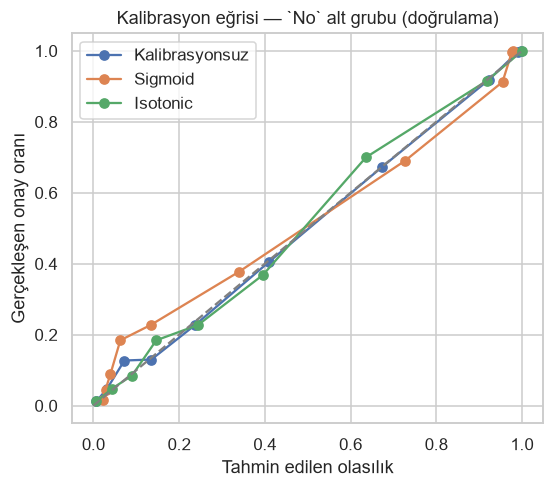

In [3]:
fig, ax = plt.subplots(figsize=(5.2, 4.6))
for name, proba in val_proba.items():
    frac, mean_pred = calibration_curve(y_val[no_default_val], proba[no_default_val], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", label=name)
ax.plot([0, 1], [0, 1], ls="--", color="gray")
ax.set(title="Kalibrasyon eğrisi — `No` alt grubu (doğrulama)",
       xlabel="Tahmin edilen olasılık", ylabel="Gerçekleşen onay oranı")
ax.legend()
plt.tight_layout()
plt.show()

In [4]:
# Decision rule: keep the plain model unless calibration lowers the no-default Brier score by more
# than 2% (relative). A calibrated wrapper also breaks the exact additivity of pred_contribs, so it
# has to earn its place.
base_brier = calib_table.loc["Kalibrasyonsuz", "Brier (`No`)"]
best_option = calib_table["Brier (`No`)"].idxmin()
improvement = (base_brier - calib_table.loc[best_option, "Brier (`No`)"]) / base_brier
calibration = best_option if (best_option != "Kalibrasyonsuz" and improvement > 0.02) else "Kalibrasyonsuz"
print(f"En düşük Brier: {best_option} (kalibrasyonsuza göre göreli iyileşme: {improvement:.2%})")
print("Karar:", calibration)

En düşük Brier: Isotonic (kalibrasyonsuza göre göreli iyileşme: 0.64%)
Karar: Kalibrasyonsuz


## 2. Karar eşiği (doğrulama seti)

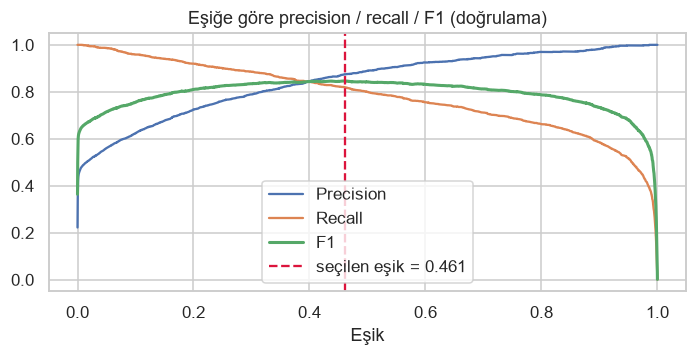

Karar eşiği: 0.4609  (0,5 yerine)


In [5]:
final_model = options[calibration]
final_val_proba = val_proba[calibration]
threshold = best_f1_threshold(y_val, final_val_proba)

precision, recall, thr = precision_recall_curve(y_val, final_val_proba)
f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(thr, precision[:-1], label="Precision")
ax.plot(thr, recall[:-1], label="Recall")
ax.plot(thr, f1, label="F1", lw=2)
ax.axvline(threshold, color="crimson", ls="--", label=f"seçilen eşik = {threshold:.3f}")
ax.set(title="Eşiğe göre precision / recall / F1 (doğrulama)", xlabel="Eşik")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Karar eşiği: {threshold:.4f}  (0,5 yerine)")

---
## 3. Test seti sonuçları

Buradan sonrası test setini kullanır. Model, kalibrasyon ve eşik yukarıda sabitlenmiştir; test
sonuçlarına bakılarak hiçbir karar değiştirilmez.

In [6]:
X_test, y_test = xy(splits.test)
test_proba = final_model.predict_proba(X_test)[:, 1]
test_result = evaluate(splits.test, test_proba, threshold)

pd.DataFrame({
    "genel": {k: v for k, v in test_result["overall"].items() if k != "confusion_matrix"},
    "`No` alt grubu": {k: v for k, v in test_result["no_default"].items() if k != "confusion_matrix"},
})

,genel,`No` alt grubu
n,"6,749.0000","3,331.0000"
positive_rate,0.2223,0.4503
roc_auc,0.9782,0.9375
pr_auc,0.9400,0.9400
f1,0.8456,0.8456
precision,0.8797,0.8797
recall,0.8140,0.8140
brier,0.0469,0.0951


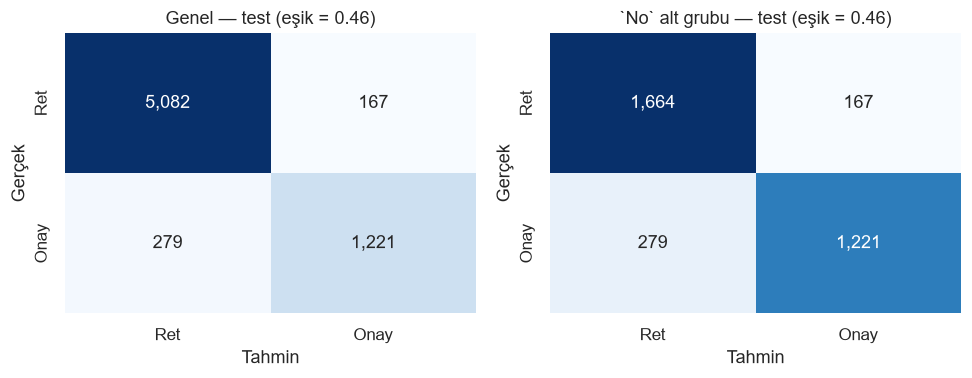

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, (title, key) in zip(axes, [("Genel", "overall"), ("`No` alt grubu", "no_default")]):
    cm = test_result[key]["confusion_matrix"]
    matrix = np.array([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]])
    sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Ret", "Onay"], yticklabels=["Ret", "Onay"])
    ax.set(title=f"{title} — test (eşik = {threshold:.2f})", xlabel="Tahmin", ylabel="Gerçek")
plt.tight_layout()
plt.show()

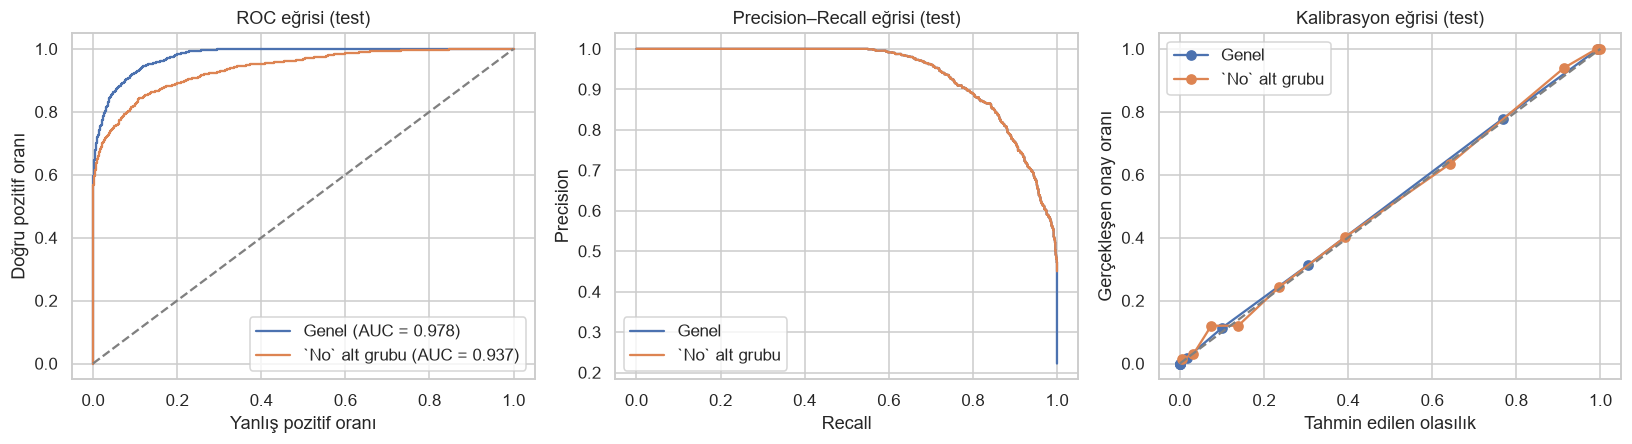

In [8]:
no_default_test = (splits.test[DEFAULT_FLAG] == "No").to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for label, mask in [("Genel", np.ones(len(y_test), dtype=bool)), ("`No` alt grubu", no_default_test)]:
    fpr, tpr, _ = roc_curve(y_test[mask], test_proba[mask])
    axes[0].plot(fpr, tpr, label=f"{label} (AUC = {roc_auc_score(y_test[mask], test_proba[mask]):.3f})")
    p, r, _ = precision_recall_curve(y_test[mask], test_proba[mask])
    axes[1].plot(r, p, label=label)
    frac, mean_pred = calibration_curve(y_test[mask], test_proba[mask], n_bins=10, strategy="quantile")
    axes[2].plot(mean_pred, frac, marker="o", label=label)
axes[0].plot([0, 1], [0, 1], ls="--", color="gray")
axes[0].set(title="ROC eğrisi (test)", xlabel="Yanlış pozitif oranı", ylabel="Doğru pozitif oranı")
axes[1].set(title="Precision–Recall eğrisi (test)", xlabel="Recall", ylabel="Precision")
axes[2].plot([0, 1], [0, 1], ls="--", color="gray")
axes[2].set(title="Kalibrasyon eğrisi (test)", xlabel="Tahmin edilen olasılık", ylabel="Gerçekleşen onay oranı")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

### Model karşılaştırması (aynı test seti)

Karşılaştırma modelleri `03` notebook'unda seçilen hiperparametrelerle eğitim setinde eğitilir; her
modelin eşiği doğrulama setinde belirlenen F1 eşiğidir.

In [9]:
others = {
    "Logistic Regression": build_pipeline(LogisticRegression(**params["logistic_regression"], max_iter=2000), linear=True),
    "Random Forest": build_pipeline(RandomForestClassifier(**params["random_forest"], random_state=RANDOM_STATE, n_jobs=4)),
    "LightGBM": build_pipeline(LGBMClassifier(**params["lightgbm"], random_state=RANDOM_STATE, n_jobs=4, verbose=-1)),
}
rows = []
for name, model in others.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append(metrics_row(name, evaluate(splits.test, proba, params["validation_f1_thresholds"][name])))
xgb_label = "XGBoost (nihai)" if calibration == "Kalibrasyonsuz" else f"XGBoost + {calibration} (nihai)"
rows.append(metrics_row(xgb_label, test_result))
test_table = pd.DataFrame(rows).set_index("model")
test_table.to_csv(REPORT_DIR / "test_comparison.csv")
test_table[["overall_roc_auc", "overall_pr_auc", "overall_f1", "overall_precision", "overall_recall", "overall_brier"]]

,overall_roc_auc,overall_pr_auc,overall_f1,overall_precision,overall_recall,overall_brier
model,,,,,,
Logistic Regression,0.9535,0.8531,0.7657,0.7500,0.7820,0.0723
Random Forest,0.9736,0.9292,0.8337,0.8192,0.8487,0.0513
LightGBM,0.9782,0.9402,0.8509,0.8758,0.8273,0.0468
XGBoost (nihai),0.9782,0.9400,0.8456,0.8797,0.8140,0.0469


**`No` alt grubu:**

In [10]:
test_table[["no_default_roc_auc", "no_default_pr_auc", "no_default_f1", "no_default_precision",
            "no_default_recall", "no_default_brier"]]

,no_default_roc_auc,no_default_pr_auc,no_default_f1,no_default_precision,no_default_recall,no_default_brier
model,,,,,,
Logistic Regression,0.8667,0.8531,0.7657,0.7500,0.7820,0.1465
Random Forest,0.9244,0.9292,0.8337,0.8192,0.8487,0.1040
LightGBM,0.9375,0.9402,0.8509,0.8758,0.8273,0.0948
XGBoost (nihai),0.9375,0.9400,0.8456,0.8797,0.8140,0.0951


## 4. Açıklanabilirlik

### 4.1 SHAP — global önem

SHAP değerleri, kalibrasyon katmanından bağımsız olarak, eğitim setinin tamamında eğitilmiş XGBoost
modeli üzerinde hesaplanır (log-odds ölçeği).

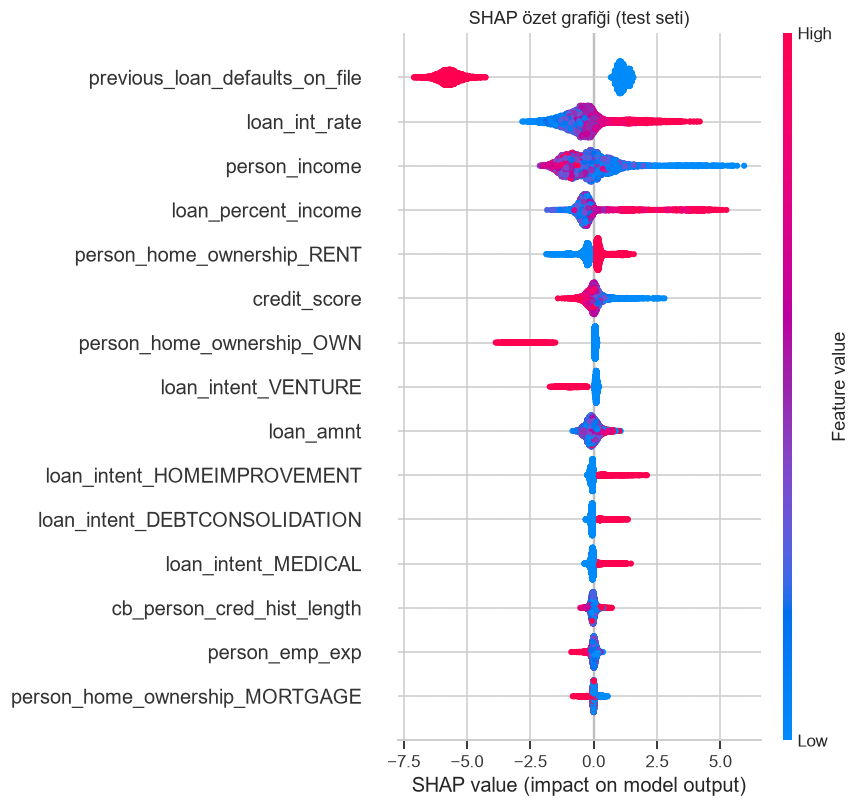

In [11]:
explain_pipe = make_xgb().fit(X_train, y_train)
pre, booster_model = explain_pipe.named_steps["preprocess"], explain_pipe.named_steps["model"]
encoded_names = list(pre.get_feature_names_out())
X_test_enc = pd.DataFrame(pre.transform(X_test), columns=encoded_names)

explainer = shap.TreeExplainer(booster_model)
shap_values = explainer(X_test_enc)

shap.summary_plot(shap_values.values, X_test_enc, show=False, max_display=15)
plt.title("SHAP özet grafiği (test seti)")
plt.tight_layout()
plt.show()

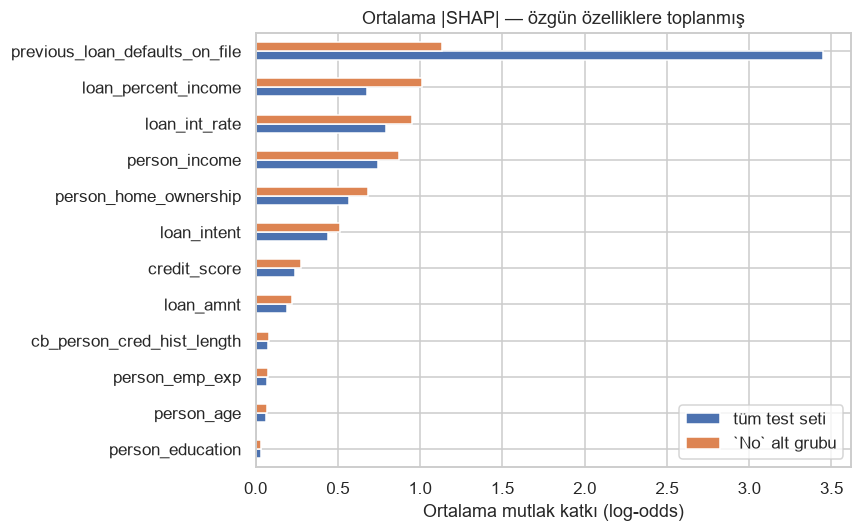

,tüm test seti,`No` alt grubu
previous_loan_defaults_on_file,3.4486,1.1337
loan_percent_income,0.6804,1.0125
loan_int_rate,0.7951,0.9518
person_income,0.7434,0.8747
person_home_ownership,0.5680,0.6823
loan_intent,0.4392,0.5129
credit_score,0.2405,0.2778
loan_amnt,0.1943,0.2201
cb_person_cred_hist_length,0.0756,0.0801
person_emp_exp,0.0705,0.0753


In [12]:
def group_contributions(values: np.ndarray, names: list[str]) -> pd.DataFrame:
    """Sum one-hot columns back onto their original feature."""
    grouped = {}
    for j, name in enumerate(names):
        origin = next((f for f in NOMINAL_FEATURES if name.startswith(f + "_")), name)
        grouped[origin] = grouped.get(origin, 0) + values[:, j]
    return pd.DataFrame(grouped)


grouped_shap = group_contributions(shap_values.values, encoded_names)
importance = pd.DataFrame({
    "tüm test seti": grouped_shap.abs().mean(),
    "`No` alt grubu": grouped_shap[no_default_test].abs().mean(),
}).sort_values("`No` alt grubu")

fig, ax = plt.subplots(figsize=(8, 5))
importance.plot.barh(ax=ax)
ax.set(title="Ortalama |SHAP| — özgün özelliklere toplanmış", xlabel="Ortalama mutlak katkı (log-odds)")
plt.tight_layout()
plt.show()
importance.sort_values("`No` alt grubu", ascending=False)

### 4.2 Etkilerin yönü

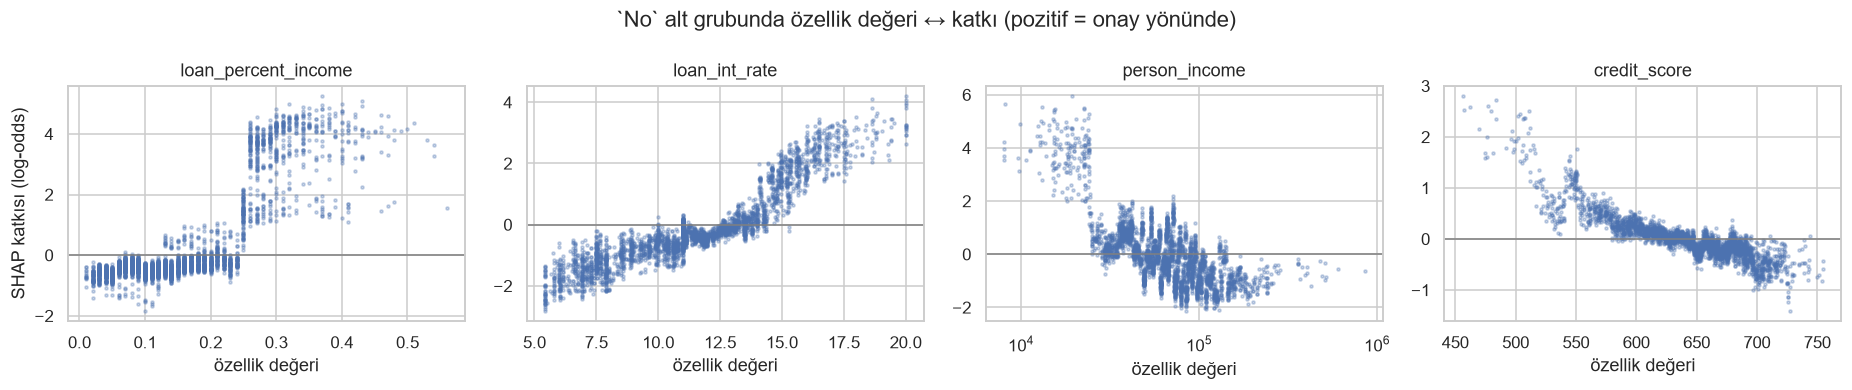

In [13]:
top = ["loan_percent_income", "loan_int_rate", "person_income", "credit_score"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col in zip(axes, top):
    ax.scatter(X_test_enc.loc[no_default_test, col], grouped_shap.loc[no_default_test, col], s=4, alpha=0.3)
    ax.axhline(0, color="gray", lw=1)
    if col == "person_income":
        ax.set_xscale("log")
    ax.set(title=col, xlabel="özellik değeri")
axes[0].set_ylabel("SHAP katkısı (log-odds)")
plt.suptitle("`No` alt grubunda özellik değeri ↔ katkı (pozitif = onay yönünde)")
plt.tight_layout()
plt.show()

### 4.3 Canlıda kullanılacak yöntem: `pred_contribs`

Sunucuya `shap` kurulmayacak; XGBoost'un yerleşik `pred_contribs=True` çıktısı kullanılacak. Aşağıda
iki yöntemin aynı sonucu verdiği ve katkıların toplamının modelin log-odds çıktısına eşit olduğu
doğrulanır.

In [14]:
dmatrix = xgb.DMatrix(X_test_enc, feature_names=encoded_names)
contribs = booster_model.get_booster().predict(dmatrix, pred_contribs=True)
margin = booster_model.get_booster().predict(dmatrix, output_margin=True)

print("SHAP ile en büyük mutlak fark      :", float(np.abs(contribs[:, :-1] - shap_values.values).max()))
print("Toplam − log-odds, en büyük fark   :", float(np.abs(contribs.sum(axis=1) - margin).max()))
print("Taban değer (bias, log-odds)        :", float(contribs[0, -1]))

SHAP ile en büyük mutlak fark      : 0.0
Toplam − log-odds, en büyük fark   : 1.430511474609375e-05
Taban değer (bias, log-odds)        : -1.3396503925323486


### 4.4 Örnek bireysel açıklamalar

In [15]:
raw_proba = explain_pipe.predict_proba(X_test)[:, 1]
grouped_contribs = group_contributions(contribs[:, :-1], encoded_names)


def explain(i: int, top_n: int = 5) -> pd.DataFrame:
    row = grouped_contribs.iloc[i]
    order = row.abs().sort_values(ascending=False).index[:top_n]
    return pd.DataFrame({
        "değer": [X_test.iloc[i][f] if f in X_test.columns else "" for f in order],
        "katkı (log-odds)": row[order].values,
        "yön": np.where(row[order].values > 0, "olumlu", "olumsuz"),
    }, index=order)


examples = {
    "Yüksek olasılık": int(np.argmax(raw_proba)),
    "Sınırda": int(np.argmin(np.abs(raw_proba - threshold))),
    "Düşük olasılık (`No` alt grubunda)": int(np.where(no_default_test)[0][np.argmin(raw_proba[no_default_test])]),
    "Geçmiş temerrüt kaydı var": int(np.where(~no_default_test)[0][0]),
}
for title, i in examples.items():
    print(f"\n{title} — olasılık {raw_proba[i]:.3f}, gerçek etiket {int(y_test.iloc[i])}")
    display(explain(i))


Yüksek olasılık — olasılık 1.000, gerçek etiket 1


,değer,katkı (log-odds),yön
loan_percent_income,0.4000,3.9938,olumlu
person_income,"8,037.0000",3.6894,olumlu
previous_loan_defaults_on_file,No,1.5126,olumlu
person_home_ownership,RENT,1.3352,olumlu
loan_intent,HOMEIMPROVEMENT,0.7813,olumlu



Sınırda — olasılık 0.461, gerçek etiket 0


,değer,katkı (log-odds),yön
previous_loan_defaults_on_file,No,1.1241,olumlu
loan_amnt,"12,000.0000",-0.3832,olumsuz
person_income,"55,974.0000",0.2507,olumlu
loan_int_rate,12.8400,-0.2501,olumsuz
person_home_ownership,RENT,0.2435,olumlu



Düşük olasılık (`No` alt grubunda) — olasılık 0.000, gerçek etiket 0


,değer,katkı (log-odds),yön
person_home_ownership,OWN,-3.0874,olumsuz
loan_int_rate,6.9200,-2.0059,olumsuz
loan_intent,VENTURE,-1.6278,olumsuz
person_income,"61,190.0000",-1.5287,olumsuz
loan_percent_income,0.1000,-0.7604,olumsuz



Geçmiş temerrüt kaydı var — olasılık 0.000, gerçek etiket 0


,değer,katkı (log-odds),yön
previous_loan_defaults_on_file,Yes,-5.7074,olumsuz
person_income,"49,130.0000",-0.9062,olumsuz
loan_intent,VENTURE,-0.6765,olumsuz
person_emp_exp,23,-0.5412,olumsuz
loan_percent_income,0.0600,-0.4352,olumsuz


## 5. Adalet denetimi (cinsiyet)

`person_gender` modele girmez, ancak diğer özellikler üzerinden dolaylı etki olabilir. Test setinde
model kararları cinsiyete göre karşılaştırılır.

In [16]:
test = splits.test.assign(proba=test_proba, pred=(test_proba >= threshold).astype(int))


def fairness_table(frame: pd.DataFrame) -> pd.DataFrame:
    out = {}
    for gender, g in frame.groupby(SENSITIVE):
        m = compute_metrics(g[TARGET], g["proba"], threshold)
        cm = m["confusion_matrix"]
        out[gender] = {
            "n": m["n"],
            "gerçek onay oranı": m["positive_rate"],
            "tahmini onay oranı": float(g["pred"].mean()),
            "ortalama olasılık": float(g["proba"].mean()),
            "TPR (recall)": m["recall"],
            "FPR": cm["fp"] / max(cm["fp"] + cm["tn"], 1),
            "precision": m["precision"],
            "ROC-AUC": m["roc_auc"],
        }
    table = pd.DataFrame(out)
    table["fark (female − male)"] = table["female"] - table["male"]
    return table


print("Tüm test seti")
fair_all = fairness_table(test)
display(fair_all)
print("`No` alt grubu")
fair_no = fairness_table(test[test[DEFAULT_FLAG] == "No"])
display(fair_no)

Tüm test seti


,female,male,fark (female − male)
n,"2,983.0000","3,766.0000",-783.0000
gerçek onay oranı,0.2152,0.2278,-0.0126
tahmini onay oranı,0.2005,0.2098,-0.0093
ortalama olasılık,0.2121,0.2239,-0.0118
TPR (recall),0.8115,0.8159,-0.0043
FPR,0.0329,0.0309,0.0019
precision,0.8712,0.8861,-0.0148
ROC-AUC,0.9789,0.9776,0.0013


`No` alt grubu


,female,male,fark (female − male)
n,"1,447.0000","1,884.0000",-437.0000
gerçek onay oranı,0.4437,0.4554,-0.0117
tahmini onay oranı,0.4133,0.4193,-0.0061
ortalama olasılık,0.4368,0.4472,-0.0103
TPR (recall),0.8115,0.8159,-0.0043
FPR,0.0957,0.0877,0.0079
precision,0.8712,0.8861,-0.0148
ROC-AUC,0.9387,0.9365,0.0022


In [17]:
rate = fair_all.loc["tahmini onay oranı"]
di_ratio = min(rate["female"], rate["male"]) / max(rate["female"], rate["male"])
print(f"Tahmini onay oranı oranı (disparate impact): {di_ratio:.3f}  (0,80 altı genellikle sorun işareti sayılır)")
print(f"TPR farkı (equal opportunity), `No` alt grubu: {fair_no.loc['TPR (recall)', 'fark (female − male)']:+.4f}")
print(f"FPR farkı, `No` alt grubu: {fair_no.loc['FPR', 'fark (female − male)']:+.4f}")

Tahmini onay oranı oranı (disparate impact): 0.956  (0,80 altı genellikle sorun işareti sayılır)
TPR farkı (equal opportunity), `No` alt grubu: -0.0043
FPR farkı, `No` alt grubu: +0.0079


## 6. Sonuçların kaydı

In [18]:
report = {
    "data_sha256": file_sha256(),
    "rows": {"train": len(splits.train), "val": len(splits.val), "test": len(splits.test)},
    "model": "xgboost",
    "calibration": calibration,
    "threshold": threshold,
    "xgboost_params": params["xgboost"],
    "test": test_result,
    "fairness": {
        "overall": fair_all.drop(columns="fark (female − male)").to_dict(),
        "no_default": fair_no.drop(columns="fark (female − male)").to_dict(),
        "disparate_impact_ratio": di_ratio,
    },
}
(REPORT_DIR / "test_report.json").write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8")
print("Yazıldı:", (REPORT_DIR / "test_report.json").relative_to(ML_ROOT))

Yazıldı: reports\phase1\test_report.json


## 7. Sonuç

**Nihai model:** XGBoost, kalibrasyonsuz, karar eşiği **0,461**.

| Test metriği | Genel | `No` alt grubu |
|---|---|---|
| ROC-AUC | 0,978 | **0,938** |
| PR-AUC | 0,940 | 0,940 |
| F1 | 0,846 | 0,846 |
| Precision | 0,880 | 0,880 |
| Recall | 0,814 | 0,814 |
| Brier | 0,047 | 0,095 |

- **Kalibrasyon:** Isotonic kalibrasyon Brier skorunu yalnızca %0,6 iyileştirdi; kalibrasyon eğrisi köşegene yakın olduğundan ek katman eklenmedi. Böylece `pred_contribs` katkıları modelin çıktısıyla birebir tutarlı kalır.
- **Test ile doğrulama uyumlu** (`No` alt grubu ROC-AUC 0,933 → 0,938); aşırı öğrenme belirtisi yok.
- **Açıklanabilirlik:** `pred_contribs` çıktısı SHAP `TreeExplainer` ile birebir aynıdır; canlıda `shap` kütüphanesine gerek yoktur. `No` alt grubunda en etkili özellikler kredi/gelir oranı, faiz oranı, gelir ve konut durumudur.
- **Adalet denetimi:** Cinsiyete göre tahmini onay oranı oranı 0,956 (0,80 eşiğinin üzerinde); `No` alt grubunda TPR farkı 0,4 puan, FPR farkı 0,8 puan. Gözlenen küçük fark, test setindeki gerçek onay oranı farkıyla (1,2 puan) aynı yöndedir. Belirgin bir dolaylı etki gözlenmedi.
- **⚠️ Etiketin yönü:** Bireysel açıklamalar EDA'daki bulguyu doğrular — model düşük geliri, yüksek kredi/gelir oranını ve kiracılığı **onay yönünde** değerlendirir. Bu, ürün kararı bekleyen açık konudur (`PROJE_PLANI.md`, Bölüm 12, madde 6).
- **Sınırlamalar:** Veri sentetiktir ve genç profile ağırlıklıdır (p99 yaş = 48); bu aralığın dışındaki profillerde tahminler daha az güvenilirdir.